# 第9章　ガウス過程による分類

温度から、次に作る試験片が合格する確率を予測します。合格なら1、不合格なら0をモデルに渡します。入力を140–180 °Cから $[0,1]$ に変換し、第8章と同じシミュレーターを使います。最初に分類器を学習し、次に潜在分布、確率の区間、獲得関数、評価指標を比較します。

In [1]:
import json

import matplotlib.pyplot as plt
import torch
from gpytorch.likelihoods import BernoulliLikelihood
from torch.distributions import Normal
from robotorchan.acquisition import BALD, PredictiveEntropy

from classification_experiment import fit_classifier, pass_probability, reveal_labels, uniforms
from experiment import BLUE, DTYPE, GREEN, INK, ORANGE, QUALITY, SEED, save_figure, setup

setup()
torch.set_default_dtype(DTYPE)
pool = torch.linspace(0, 1, 81, dtype=DTYPE).unsqueeze(-1)
indices = torch.tensor([0, 12, 26, 40, 50, 64, 74, 80])
draws = uniforms(pool, SEED + 9)
train_x = pool[indices]
train_y = reveal_labels(train_x, draws[indices])
model = fit_classifier(train_x, train_y, seed=SEED + 9, epochs=120)
test_x = (torch.arange(120, dtype=DTYPE) + 0.37).unsqueeze(-1) / 120
assert not torch.isclose(test_x, pool.T).any()
decision_threshold = 0.5
with torch.no_grad():
    probabilities = model.predict_proba(test_x)
    p = probabilities[..., 1]
    decisions = model.predict_class(test_x, threshold=decision_threshold)
assert probabilities.shape == (120, 2)
torch.testing.assert_close(probabilities.sum(-1), torch.ones_like(p))
print("初期ラベル:", train_y[:, 0].int().tolist())
print(f"評価配列の先頭温度: {140 + 40 * test_x[0].item():.2f} °C、合格確率: {p[0]:.3f}")

初期ラベル: [0, 1, 1, 1, 0, 0, 0, 1]
評価配列の先頭温度: 140.12 °C、合格確率: 0.468


## 9.2 潜在スコア・確率・ラベル

潜在スコアは無次元の実数です。GPyTorchの `BernoulliLikelihood` では、標準正規分布の累積分布関数 $\Phi$ で確率に変換します。変分学習で得た点ごとの潜在事後が $\mathcal N(m,s^2)$ であるとき、平均合格確率は $\Phi(m/\sqrt{1+s^2})$ です。`predict_proba` の結果と照合します。

灰色の破線は模擬試験の真の合格確率です。実試験では通常この線を描けません。青い帯は変分モデルで求めた潜在スコアまたは合格確率の点ごとの95%信用区間で、次の0/1ラベルの範囲ではありません。

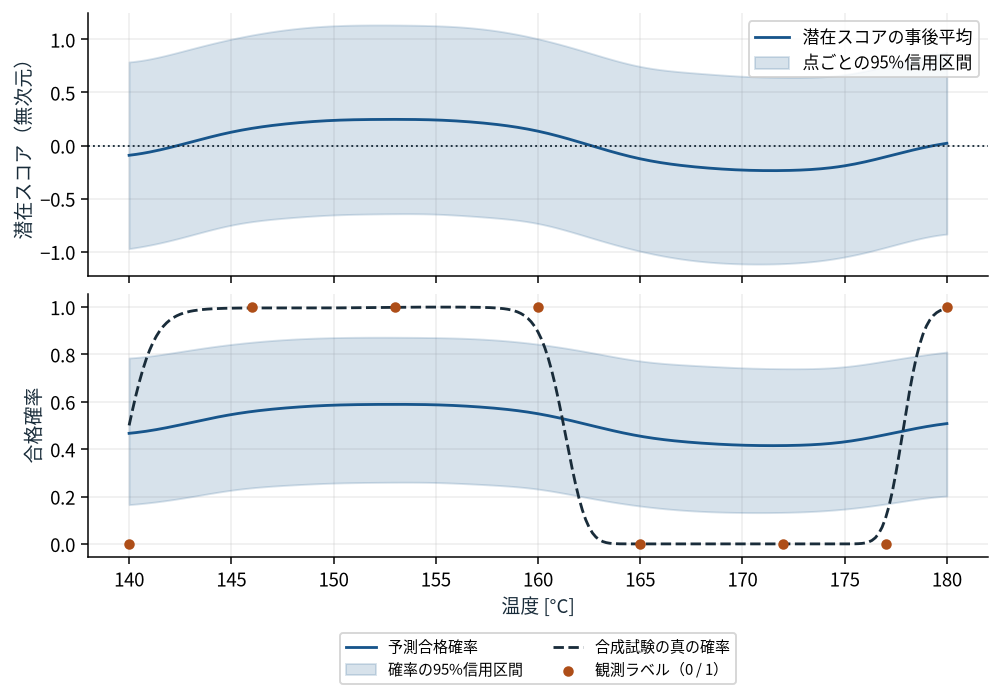

In [2]:
grid = torch.linspace(0, 1, 241, dtype=DTYPE).unsqueeze(-1)
temperature = 140 + 40 * grid[:, 0]
with torch.no_grad():
    latent = model.latent_posterior(grid)
    m = latent.mean.reshape(-1)
    sd = latent.variance.reshape(-1).sqrt()
    p_grid = model.predict_proba(grid)[..., 1]
    probability_posterior = model.probability_posterior(grid)
    lower, upper = probability_posterior.credible_interval(0.95)
    lower, upper = lower[..., 1], upper[..., 1]
z = torch.special.ndtri(torch.tensor(0.975))
p_probit = torch.special.ndtr(m / torch.sqrt(1 + sd.square()))
assert isinstance(model.likelihood, BernoulliLikelihood)
torch.testing.assert_close(p_grid, p_probit, atol=1e-10, rtol=1e-10)
torch.testing.assert_close(lower, torch.special.ndtr(m - z * sd), atol=1e-10, rtol=1e-10)
torch.testing.assert_close(upper, torch.special.ndtr(m + z * sd), atol=1e-10, rtol=1e-10)
fig, axes = plt.subplots(2, 1, figsize=(7.3, 5.05), sharex=True, layout="constrained")
top, bottom = axes
top.plot(temperature, m, color=BLUE, label="潜在スコアの事後平均")
top.fill_between(temperature, m - z * sd, m + z * sd, color=BLUE, alpha=0.17,
                 label="点ごとの95%信用区間")
top.axhline(0, color=INK, linestyle=":", linewidth=1)
top.set(ylabel="潜在スコア（無次元）")
top.legend(fontsize=9, loc="upper right")
bottom.plot(temperature, p_grid, color=BLUE, label="予測合格確率")
bottom.fill_between(temperature, lower, upper, color=BLUE, alpha=0.17,
                    label="確率の95%信用区間")
bottom.plot(temperature, pass_probability(grid)[:, 0], color=INK, linestyle="--",
            label="合成試験の真の確率")
bottom.scatter(140 + 40 * train_x[:, 0], train_y[:, 0], color=ORANGE, s=21,
               label="観測ラベル（0 / 1）", zorder=5)
bottom.set(xlabel="温度 [°C]", ylabel="合格確率", ylim=(-0.055, 1.055))
bottom.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.26))
save_figure(fig, "ch09_latent_probability")

## 9.3 何が解析的で、何が近似か

GP事前とBernoulli尤度を掛けた事後は一般に正規分布になりません。`make_mll` が組み立てる `VariationalELBO` で近似分布を学習します。学習済みの近似正規分布に対するProbitの積分は閉形式です。下では、平均合格確率と全分散の法則を別の計算方法でも確認します。

In [3]:
from gpytorch.utils.quadrature import GaussHermiteQuadrature1D

with torch.no_grad():
    quadrature = GaussHermiteQuadrature1D(num_locs=48).to(grid)
    p_quadrature = quadrature(torch.special.ndtr, latent.distribution).flatten()
    conditional_noise = quadrature(
        lambda f: torch.special.ndtr(f) * torch.special.ndtr(-f), latent.distribution
    ).flatten()
    probability_variance = model.probability_variance(grid)[..., 1]
    label_variance = p_grid * (1 - p_grid)
torch.testing.assert_close(p_quadrature, p_grid, atol=2e-6, rtol=2e-6)
torch.testing.assert_close(conditional_noise + probability_variance, label_variance,
                           atol=2e-6, rtol=2e-6)
assert model.make_mll(num_data=len(train_x)).__class__.__name__ == "VariationalELBO"
example = Normal(torch.tensor(0.0), torch.tensor(1.0))
print("同じ潜在値2の逆リンク Probit / Logit:", example.cdf(torch.tensor(2.0)).item(),
      torch.sigmoid(torch.tensor(2.0)).item())

同じ潜在値2の逆リンク Probit / Logit: 0.9772498680518208 0.8807970779778823


## 9.4 次の試験と、その後の評価

既知の試験片を除き、予測エントロピーとBALDの候補を表示します。ここではBALDの1点だけを測り、9件で学習し直します。Brier損失・対数損失・誤分類率は、学習や候補選びから独立した温度と模擬ラベルで評価します。今回の有限標本による評価は、第8章の条件付き期待値による評価と区別します。

{
  "train_temperatures_c": [
    140.0,
    146.0,
    153.0,
    160.0,
    165.0,
    172.0,
    177.0,
    180.0
  ],
  "train_labels": [
    0,
    1,
    1,
    1,
    0,
    0,
    0,
    1
  ],
  "held_out_count": 120,
  "held_out_positives": 68,
  "first_test_temperature_c": 140.12333333333333,
  "first_test_p": 0.4676467815652827,
  "probit_max_abs_error": 1.1102230246251565e-16,
  "quadrature_max_abs_error": 3.3306690738754696e-16,
  "total_variance_max_abs_error": 8.326672684688674e-17,
  "entropy_temperature_c": 162.5,
  "bald_temperature_c": 149.5,
  "new_label": 1,
  "before": {
    "brier": 0.20036572128135527,
    "log_loss": 0.5931388034889333,
    "error_rate": 0.10833333333333334
  },
  "after": {
    "brier": 0.15749928961942122,
    "log_loss": 0.5013877156545641,
    "error_rate": 0.10833333333333334
  }
}


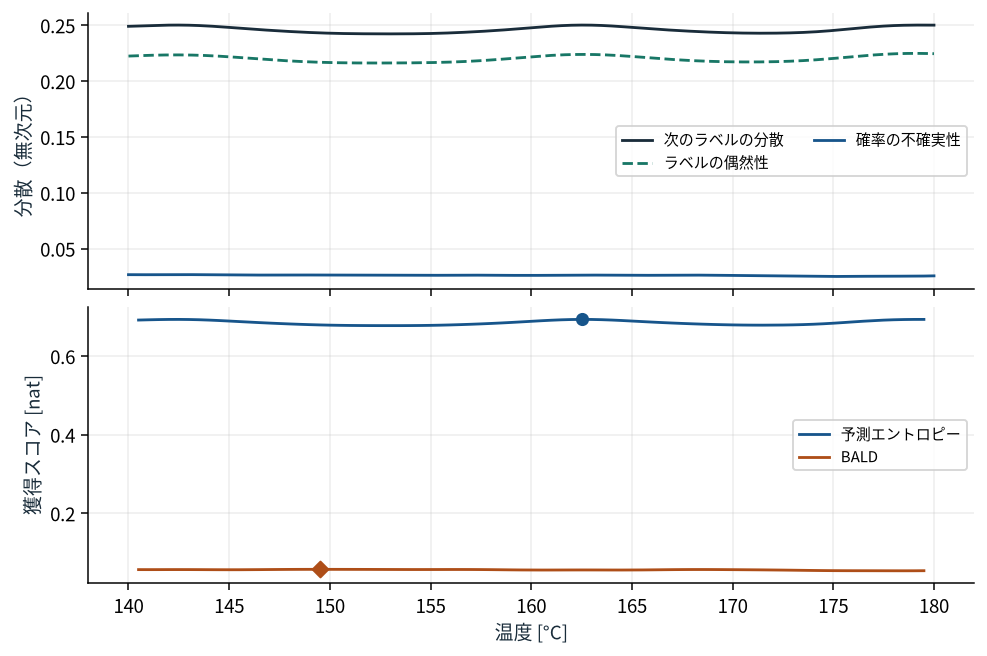

In [4]:
available = torch.ones(len(pool), dtype=torch.bool)
available[indices] = False
remaining = torch.where(available)[0]
cand_x = pool[remaining].unsqueeze(-2)
with torch.no_grad():
    h_pred = PredictiveEntropy(model)(cand_x)
    information = BALD(model)(cand_x)
entropy_index = remaining[h_pred.argmax()]
bald_index = remaining[information.argmax()]
new_x = pool[bald_index].reshape(1, 1)
new_y = reveal_labels(new_x, draws[bald_index].reshape(1, 1))
updated = fit_classifier(torch.cat((train_x, new_x)), torch.cat((train_y, new_y)),
                         seed=SEED + 9, epochs=120)

held_out_labels = reveal_labels(test_x, uniforms(test_x, SEED + 1009)).reshape(-1)


def report_scores(classifier):
    with torch.no_grad():
        probability = classifier.predict_proba(test_x)[..., 1]
        safe = probability.clamp(1e-12, 1 - 1e-12)
        predicted = classifier.predict_class(test_x, threshold=decision_threshold)
        return {
            "brier": (probability - held_out_labels).square().mean().item(),
            "log_loss": -(held_out_labels * safe.log() + (1 - held_out_labels) * torch.log1p(-safe)).mean().item(),
            "error_rate": (predicted != held_out_labels).to(DTYPE).mean().item(),
        }


before = report_scores(model)
after = report_scores(updated)
fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.75), sharex=True, layout="constrained")
top, bottom = axes
top.plot(temperature, label_variance, color=INK, label="次のラベルの分散")
top.plot(temperature, conditional_noise, color=GREEN, linestyle="--", label="ラベルの偶然性")
top.plot(temperature, probability_variance, color=BLUE, label="確率の不確実性")
top.set(ylabel="分散（無次元）")
top.legend(fontsize=8, ncol=2)
candidate_t = 140 + 40 * pool[remaining, 0]
bottom.plot(candidate_t, h_pred, color=BLUE, label="予測エントロピー")
bottom.plot(candidate_t, information, color=ORANGE, label="BALD")
bottom.scatter(140 + 40 * pool[entropy_index, 0], h_pred.max(), color=BLUE, zorder=4)
bottom.scatter(140 + 40 * pool[bald_index, 0], information.max(), color=ORANGE, marker="D", zorder=4)
bottom.set(xlabel="温度 [°C]", ylabel="獲得スコア [nat]")
bottom.legend(fontsize=8, loc="center right")
save_figure(fig, "ch09_uncertainty_queries")

metrics = {
    "train_temperatures_c": (140 + 40 * train_x[:, 0]).tolist(),
    "train_labels": train_y[:, 0].int().tolist(),
    "held_out_count": len(test_x), "held_out_positives": int(held_out_labels.sum()),
    "first_test_temperature_c": 140 + 40 * test_x[0].item(), "first_test_p": p[0].item(),
    "probit_max_abs_error": (p_grid - p_probit).abs().max().item(),
    "quadrature_max_abs_error": (p_grid - p_quadrature).abs().max().item(),
    "total_variance_max_abs_error": (conditional_noise + probability_variance - label_variance).abs().max().item(),
    "entropy_temperature_c": 140 + 40 * pool[entropy_index].item(),
    "bald_temperature_c": 140 + 40 * new_x.item(), "new_label": int(new_y.item()),
    "before": before, "after": after,
}
print(json.dumps(metrics, indent=2, ensure_ascii=False))
(QUALITY / "ch09_metrics.json").write_text(json.dumps(metrics, indent=2) + chr(10), encoding="utf-8")

同じ120ラベルを再利用して前後を比べます。この可視化は、1件の追加で何が起きるかを追うための例です。複数シードでの方策の比較は第8章を参照してください。